# Part 4. Model comparison and error analysis

This notebook puts all four models from Parts 2 and 3 side by side on the same 842 test emails, next to the majority baseline, and then looks hard at their mistakes. Every model gets scored on exactly the same rows by exactly the same code.

Part 3 saved its test predictions, so Random Forest and KNN are read straight from disk. Part 2 only saved a summary table. So this notebook rebuilds logistic regression and the decision tree from the settings in Part 2's notebook, and it won't go on unless the rebuilt models give back Part 2's reported scores exactly.

Spam is the positive class (`1`). A false positive (FP) means a real email got sent to the spam folder. Spam that slips into the inbox is a false negative (FN). Tables go to `results/part4/` and figures to `figures/part4/`, and nothing from Parts 1 to 3 is changed.

## 1. Setup

In [1]:
import sys
import json
from itertools import combinations
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)

from src.config import RANDOM_STATE, FIGURES_DIR, RESULTS_DIR
from src.data import get_train_test

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

OUT = RESULTS_DIR / "part4"
FIG = FIGURES_DIR / "part4"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Same look as the Part 1 figures.
INK, INK2, GRID, NEUTRAL = "#0b0b0b", "#52514e", "#e5e4e0", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

def save_plot(fig, name):
    fig.savefig(FIG / name)
    plt.show()
    plt.close(fig)

def scores(y_true, probability, threshold=0.5):
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    recall, specificity = tp / (tp + fn), tn / (tn + fp)
    return {"accuracy": (tp + tn) / len(y_true),
            "balanced_accuracy": (recall + specificity) / 2,
            "precision": tp / (tp + fp) if tp + fp else 0.0,
            "recall": recall, "specificity": specificity,
            "f1": 2 * tp / (2 * tp + fp + fn),
            "roc_auc": roc_auc_score(y_true, probability),
            "average_precision": average_precision_score(y_true, probability),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def strict_threshold(y_true, probability):
    # Part 3's rule. Highest recall with at least 98% precision and at least 20 spam flags,
    # ties go to fewer false positives and then the higher threshold.
    precision, recall, candidates = precision_recall_curve(y_true, probability)
    table = pd.DataFrame({"threshold": candidates, "precision": precision[:-1], "recall": recall[:-1],
                          "flagged": [(probability >= t).sum() for t in candidates],
                          "fp": [((probability >= t) & (y_true == 0)).sum() for t in candidates]})
    eligible = table[(table.precision >= 0.98) & (table.flagged >= 20)]
    if eligible.empty:
        return float(np.nextafter(1.0, 2.0))
    return float(eligible.sort_values(["recall", "fp", "threshold"], ascending=[False, True, False])
                 .iloc[0].threshold)

METRICS = ["accuracy", "balanced_accuracy", "precision", "recall", "specificity",
           "f1", "roc_auc", "average_precision"]
LABELS = {"accuracy": "Accuracy", "balanced_accuracy": "Balanced acc.", "precision": "Precision",
          "recall": "Recall", "specificity": "Specificity", "f1": "F1",
          "roc_auc": "ROC-AUC", "average_precision": "AP"}

## 2. Load and rebuild every model's test predictions

The comparison only means something if every model is scored on the same emails. So the first cell checks that Part 3's saved predictions cover exactly the 842 test rows from `get_train_test()` with the same true labels, then lines everything up by `cleaned_row_id`.

Each model is the final version its part picked before anyone looked at the test set. For Random Forest and KNN that's Part 3's tuned models. Tuning barely moved Random Forest anyway (mean CV AP went up by 0.0005), so the default and tuned forests are basically the same model.

The second cell rebuilds Part 2's models. That's scaled logistic regression with default settings, plus the tuned tree (max depth 10, at least 10 samples to split). Both have to match all five scores in `results/02_model_metrics.csv`. The cell also scores them with CV on Part 3's five folds, so all four models share the same folds, and the tree's grid search runs again inside each training fold the way Part 3 ran its nested CV. Then it applies Part 3's strict threshold rule (highest recall with at least 98% precision on out of fold predictions) to both. The rule gets tested first, by checking that it gives back Part 3's own thresholds.

In [2]:
X_train, X_test, y_train, y_test = get_train_test()
y = y_test.to_numpy()

# Fixed colors per model, checked for colorblind separation. RF and KNN keep their Part 3 colors.
COLORS = {"Majority baseline": NEUTRAL, "Logistic Regression": "#1baf7a",
          "Decision Tree": "#4a3aa7", "Random Forest": "#2a78d6", "KNN": "#eb6834"}
PART3_NAMES = {"Majority baseline": "Majority baseline", "Random Forest": "RF tuned", "KNN": "KNN tuned"}

part3 = RESULTS_DIR / "part3"
saved = pd.read_csv(part3 / "test_predictions.csv").set_index("cleaned_row_id")
assert set(saved.index) == set(X_test.index), "Part 3 was scored on a different test set"
saved = saved.loc[X_test.index]
assert (saved["true_label"].to_numpy() == y).all()
probabilities = {name: saved[old + "_probability"].to_numpy() for name, old in PART3_NAMES.items()}

locked = json.loads((part3 / "locked_settings.json").read_text())
strict_thresholds = {"Random Forest": locked["thresholds"]["RF"], "KNN": locked["thresholds"]["KNN"]}
cv = pd.read_csv(part3 / "cv_fold_metrics.csv")
cv = cv[cv.model.isin(PART3_NAMES.values())].replace({"model": {old: name for name, old in PART3_NAMES.items()}})
folds = (pd.read_csv(part3 / "cv_assignments.csv").set_index("cleaned_row_id")
         .loc[X_train.index, "outer_fold"].to_numpy())

# Part 4 reuses Part 3's threshold rule on new models, so check it gives back Part 3's own thresholds.
part3_oof = pd.read_csv(part3 / "oof_probabilities.csv").set_index("cleaned_row_id").loc[X_train.index]
for name in ["Random Forest", "KNN"]:
    assert np.isclose(strict_threshold(y_train.to_numpy(), part3_oof[PART3_NAMES[name]].to_numpy()),
                      strict_thresholds[name])
print("Test emails:", len(y), "| spam:", int(y.sum()), f"({y.mean():.1%})")

Test emails: 842 | spam: 336 (39.9%)


In [3]:
# Part 2's final models, with the settings from notebooks/02_Logistic_DecisionTree.ipynb.
PART2_MODELS = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=10,
                                            min_samples_split=10, min_samples_leaf=1),
}
PART2_GRID = {"max_depth": [3, 5, 10, 15, None], "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 5]}

reported = pd.read_csv(
    RESULTS_DIR / "part2" / "02_model_metrics.csv"
).set_index("Model")
fitted_part2 = {}
for name, model in PART2_MODELS.items():
    fitted_part2[name] = clone(model).fit(X_train, y_train)
    probabilities[name] = fitted_part2[name].predict_proba(X_test)[:, 1]
    mine = scores(y, probabilities[name])
    for key, column in [("accuracy", "Accuracy"), ("precision", "Precision"), ("recall", "Recall"),
                        ("f1", "F1"), ("roc_auc", "ROC AUC")]:
        assert np.isclose(mine[key], reported.loc[name, column]), (name, key)
print("Rebuilt Part 2 models match results/part2/02_model_metrics.csv exactly")

# CV on Part 3's five outer folds. The tree's grid search runs again inside each training fold,
# the same nested setup Part 3 used, so tuning never sees the rows it's scored on.
part2_cv = []
for name, model in PART2_MODELS.items():
    oof = np.full(len(X_train), np.nan)
    for fold in range(1, 6):
        fit_rows, check_rows = folds != fold, folds == fold
        estimator = (GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), PART2_GRID, cv=5, scoring="f1")
                     if name == "Decision Tree" else clone(model))
        estimator.fit(X_train[fit_rows], y_train[fit_rows])
        oof[check_rows] = estimator.predict_proba(X_train[check_rows])[:, 1]
        part2_cv.append({"model": name, "fold": fold, **scores(y_train[check_rows].to_numpy(), oof[check_rows])})
    threshold = strict_threshold(y_train.to_numpy(), oof)
    if threshold <= 1:
        strict_thresholds[name] = threshold
    else:
        # Part 3's rule finds nothing that qualifies, so this model only gets scored at 0.5.
        precision, _, candidates = precision_recall_curve(y_train, oof)
        flagged = np.array([(oof >= t).sum() for t in candidates])
        top = oof == oof.max()
        highest = np.argsort(-oof, kind="stable")[:50]
        print(f"{name}: no threshold reaches 98% precision on out-of-fold predictions "
              f"(best with at least 20 flags is {precision[:-1][flagged >= 20].max():.1%}). "
              f"{int(top.sum())} emails tie for its top score and {int((top & (y_train == 0)).sum())} of them are real. "
              f"{int((y_train.to_numpy()[highest] == 0).sum())} of its 50 highest scores are real emails.")
part2_cv = pd.DataFrame(part2_cv)
part2_cv.to_csv(OUT / "part2_models_cv_folds.csv", index=False)
cv = pd.concat([cv, part2_cv], ignore_index=True)

MODELS = ["Majority baseline", "Logistic Regression", "Decision Tree", "Random Forest", "KNN"]
REAL = MODELS[1:]
SHORT = {"Logistic Regression": "LR", "Decision Tree": "DT", "Random Forest": "RF", "KNN": "KNN"}
probabilities = {name: probabilities[name] for name in MODELS}
with open(OUT / "strict_thresholds.json", "w") as file:
    json.dump({name: strict_thresholds.get(name) for name in REAL}, file, indent=2)
print("Strict thresholds picked on out-of-fold predictions",
      {name: round(t, 4) for name, t in strict_thresholds.items()})

Rebuilt Part 2 models match results/part2/02_model_metrics.csv exactly
Logistic Regression: no threshold reaches 98% precision on out-of-fold predictions (best with at least 20 flags is 97.7%). 4 emails tie for its top score and 0 of them are real. 3 of its 50 highest scores are real emails.
Decision Tree: no threshold reaches 98% precision on out-of-fold predictions (best with at least 20 flags is 92.0%). 645 emails tie for its top score and 73 of them are real. 5 of its 50 highest scores are real emails.
Strict thresholds picked on out-of-fold predictions {'Random Forest': 0.735, 'KNN': 0.6332}


Neither of Part 2's models can meet the strict rule. On out of fold predictions, the best logistic regression can do while flagging at least 20 emails is 97.7% precision, and the tree tops out at 92.0%. The tree's problem is easy to see. Every email in a leaf gets the same score, and 646 emails tie for its top score, 72 of them real. There's no small, very sure group to pick out. Logistic regression is closer, but 3 of its 50 most confident calls are still real emails. So both get scored at the default threshold of 0.5 from here on, and only Random Forest and KNN have a strict threshold.

## 3. Test metrics with 95% intervals

Accuracy alone is misleading here. About 40% of the test emails are spam, so a baseline that calls everything real mail already gets 0.601. That's why the table has eight metrics. Recall is the share of spam caught. Specificity is the share of real email left alone, and balanced accuracy is just the average of the two, so the 60/40 split can't inflate it. Average precision (AP) sums up the whole precision and recall curve, and its floor is the spam rate (0.399), not 0.5.

One split gives one number per metric. That number hides how lucky or unlucky the split was. So the test rows get resampled with replacement 2,000 times, and the middle 95% of each metric becomes its interval [1]. All models share the same resamples. That's what makes the pairwise comparison in section 7 possible.

In [4]:
# One set of resampled test rows shared by every model, so model differences are paired.
rng = np.random.default_rng(RANDOM_STATE)
boot_rows = rng.integers(0, len(y), size=(2000, len(y)))
boot = {name: pd.DataFrame([scores(y[rows], probabilities[name][rows]) for rows in boot_rows])
        for name in MODELS}

table_rows = []
for name in MODELS:
    point = scores(y, probabilities[name])
    for metric in METRICS:
        low, high = np.percentile(boot[name][metric], [2.5, 97.5])
        table_rows.append({"model": name, "metric": metric, "value": point[metric],
                           "ci_low": low, "ci_high": high})
test_table = pd.DataFrame(table_rows)
test_table.to_csv(OUT / "test_metrics_with_ci.csv", index=False)

counts = pd.DataFrame({name: scores(y, probabilities[name]) for name in MODELS}).T[["fp", "fn"]].astype(int)
report_table = (test_table.pivot(index="model", columns="metric", values="value")
                .loc[list(MODELS), METRICS].rename(columns=LABELS).join(counts.rename(columns=str.upper)))
report_table.to_csv(OUT / "comparison_table.csv")
display(report_table.round(3))

ci_text = test_table.assign(cell=[f"{v:.3f} [{lo:.3f}, {hi:.3f}]" for v, lo, hi in
                                  zip(test_table.value, test_table.ci_low, test_table.ci_high)])
display(ci_text.pivot(index="model", columns="metric", values="cell").loc[list(MODELS), METRICS]
        .rename(columns=LABELS))

,Accuracy,Balanced acc.,Precision,Recall,Specificity,F1,ROC-AUC,AP,FP,FN
model,,,,,,,,,,
Majority baseline,0.601,0.500,0.000,0.000,1.000,0.000,0.500,0.399,0,336
Logistic Regression,0.935,0.930,0.930,0.905,0.955,0.917,0.977,0.962,23,32
Decision Tree,0.909,0.903,0.894,0.875,0.931,0.884,0.922,0.887,35,42
Random Forest,0.943,0.939,0.936,0.920,0.958,0.928,0.990,0.984,21,27
KNN,0.917,0.901,0.962,0.824,0.978,0.888,0.980,0.968,11,59


metric,Accuracy,Balanced acc.,Precision,Recall,Specificity,F1,ROC-AUC,AP
model,,,,,,,,
Majority baseline,"0.601 [0.569, 0.633]","0.500 [0.500, 0.500]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","1.000 [1.000, 1.000]","0.000 [0.000, 0.000]","0.500 [0.500, 0.500]","0.399 [0.367, 0.431]"
Logistic Regression,"0.935 [0.917, 0.950]","0.930 [0.911, 0.946]","0.930 [0.901, 0.955]","0.905 [0.871, 0.935]","0.955 [0.935, 0.971]","0.917 [0.894, 0.937]","0.977 [0.967, 0.986]","0.962 [0.941, 0.979]"
Decision Tree,"0.909 [0.887, 0.928]","0.903 [0.881, 0.923]","0.894 [0.862, 0.925]","0.875 [0.838, 0.910]","0.931 [0.908, 0.951]","0.884 [0.857, 0.909]","0.922 [0.898, 0.945]","0.887 [0.851, 0.920]"
Random Forest,"0.943 [0.925, 0.958]","0.939 [0.921, 0.956]","0.936 [0.907, 0.961]","0.920 [0.888, 0.948]","0.958 [0.939, 0.975]","0.928 [0.906, 0.948]","0.990 [0.984, 0.994]","0.984 [0.974, 0.992]"
KNN,"0.917 [0.897, 0.935]","0.901 [0.878, 0.922]","0.962 [0.938, 0.982]","0.824 [0.781, 0.865]","0.978 [0.965, 0.990]","0.888 [0.859, 0.913]","0.980 [0.972, 0.987]","0.968 [0.949, 0.982]"


## 4. Cross validation results

The test set is only 842 emails. The five outer folds from Part 3 give a second look that never touches the test rows, and the spread across folds shows how much the scores bounce around. Every tuned model gets nested CV, where the tuning happens inside each fold, and logistic regression, which wasn't tuned, gets plain CV on the same folds.

In [5]:
cv["specificity"] = cv.tn / (cv.tn + cv.fp)
cv["balanced_accuracy"] = (cv.recall + cv.specificity) / 2
cv_summary = cv.groupby("model")[METRICS].agg(["mean", "std"]).loc[list(MODELS)]
cv_summary.to_csv(OUT / "cv_summary_all_models.csv")
display(pd.DataFrame({LABELS[m]: [f"{cv_summary.loc[n, (m, 'mean')]:.3f} ± {cv_summary.loc[n, (m, 'std')]:.3f}"
                                  for n in MODELS] for m in METRICS}, index=list(MODELS)))

# The model picked for the deeper error analysis is chosen on CV, never on the test set.
best = cv_summary[("average_precision", "mean")].drop("Majority baseline").idxmax()
print("Best model by mean CV average precision:", best)

,Accuracy,Balanced acc.,Precision,Recall,Specificity,F1,ROC-AUC,AP
Majority baseline,0.601 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.399 ± 0.000
Logistic Regression,0.921 ± 0.009,0.915 ± 0.011,0.917 ± 0.013,0.882 ± 0.027,0.947 ± 0.010,0.899 ± 0.012,0.969 ± 0.007,0.945 ± 0.017
Decision Tree,0.912 ± 0.011,0.906 ± 0.013,0.903 ± 0.019,0.873 ± 0.024,0.938 ± 0.014,0.888 ± 0.015,0.917 ± 0.011,0.864 ± 0.017
Random Forest,0.947 ± 0.010,0.943 ± 0.012,0.947 ± 0.017,0.920 ± 0.023,0.965 ± 0.011,0.933 ± 0.013,0.982 ± 0.007,0.977 ± 0.011
KNN,0.896 ± 0.011,0.875 ± 0.014,0.962 ± 0.014,0.771 ± 0.034,0.979 ± 0.008,0.856 ± 0.018,0.970 ± 0.007,0.962 ± 0.008


Best model by mean CV average precision: Random Forest


Random Forest comes out on top. It has the best test F1, 0.928 [0.906, 0.948], and the best AP, 0.984 [0.974, 0.992], and CV agrees (F1 0.932 ± 0.014, AP 0.977 ± 0.011). Logistic regression is a close second at F1 0.917 [0.894, 0.937], and its interval overlaps Random Forest's almost completely. KNN and the tree land a step lower on F1 (0.888 and 0.884), but for very different reasons. KNN plays it safe and has the best precision and specificity of anyone. The tree is mediocre everywhere and has by far the worst AP (0.887).

Test scores mostly sit close to the CV means. Logistic regression and KNN do a bit better on test than in CV, by about one and a half fold standard deviations, which isn't unusual. For KNN it also makes sense that the final model, which could search all the training rows for neighbors, beats CV models that only had four fifths of them.

Random Forest has the best mean CV AP, so it's the model used for the deeper error analysis in section 9. Picking it on CV instead of the test set keeps the test set honest.

## 5. Confusion matrices

Each cell shows the count and, under it, the share of that true class, so each row adds up to 100%. The baseline is left out since its matrix is trivial, with all 506 real emails right and all 336 spams missed. Everything uses the default threshold of 0.5.

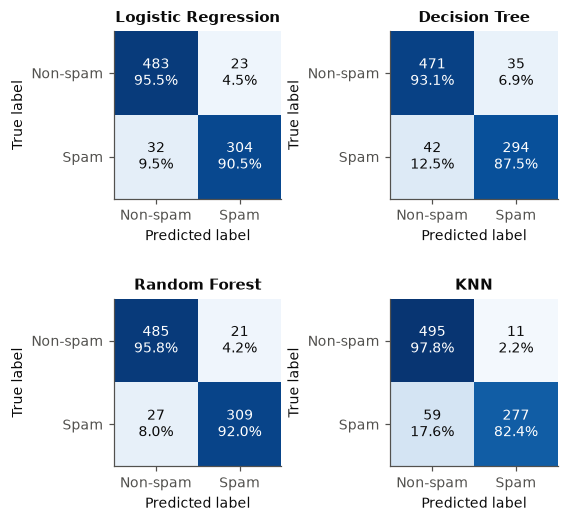

In [6]:
ncols = min(len(REAL), 2)
nrows = int(np.ceil(len(REAL) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.5 * nrows), squeeze=False)
for ax, name in zip(axes.flat, REAL):
    matrix = confusion_matrix(y, (probabilities[name] >= 0.5).astype(int), labels=[0, 1])
    share = matrix / matrix.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matrix[i, j]}\n{share[i, j]:.1%}", ha="center", va="center",
                    fontsize=9, color="white" if share[i, j] > 0.5 else INK)
    ax.set_xticks([0, 1], ["Non-spam", "Spam"])
    ax.set_yticks([0, 1], ["Non-spam", "Spam"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(name)
    ax.grid(False)
for ax in list(axes.flat)[len(REAL):]:
    ax.axis("off")
fig.tight_layout()
save_plot(fig, "01_confusion_matrices.png")

Fig. 1 shows four pretty different error patterns. Random Forest makes the fewest mistakes, 21 false alarms and 27 missed spams. Logistic regression is close behind with 23 and 32. The tree makes the most, 35 false alarms (6.9% of real email) and 42 misses. KNN is the lopsided one. It hardly ever flags real mail (2.2%) but misses 17.6% of spam, about twice the rate of Random Forest or logistic regression.

Most of KNN's misses have a simple cause. Its missed spams are short, with a median of just 5 tracked words present, which is about what a typical real email has (6). In distance terms those spams sit right in the crowd of real mail, so their nearest neighbors vote them real. Section 9 shows KNN catching only 59% of spam with four or fewer tracked words, while the other three models catch 71% to 75%.

## 6. Comparison graphs

Fig. 2 puts the main metrics on one scale with their 95% intervals. The baseline isn't drawn because its recall and F1 are both 0 and would squash everything else. Fig. 3 zooms in on the top corner of the ROC and precision and recall curves, since that's where the models differ. Dots mark the 0.5 threshold. Stars mark Part 3's strict threshold, which only Random Forest and KNN have.

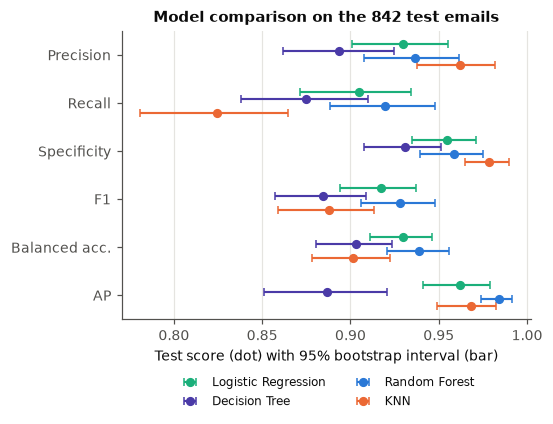

In [7]:
show = ["precision", "recall", "specificity", "f1", "balanced_accuracy", "average_precision"]
offsets = np.linspace(-0.22, 0.22, len(REAL)) if len(REAL) > 1 else [0.0]
fig, ax = plt.subplots(figsize=(4.8, 3.4))
for offset, name in zip(offsets, REAL):
    part = test_table[test_table.model == name].set_index("metric").loc[show]
    ax.errorbar(part.value, np.arange(len(show)) + offset,
                xerr=[part.value - part.ci_low, part.ci_high - part.value],
                fmt="o", ms=5, lw=1.4, capsize=2.5, color=COLORS[name], label=name)
ax.set_yticks(range(len(show)), [LABELS[m] for m in show])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Test score (dot) with 95% bootstrap interval (bar)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=8)
ax.set_title("Model comparison on the 842 test emails")
save_plot(fig, "02_metric_comparison.png")

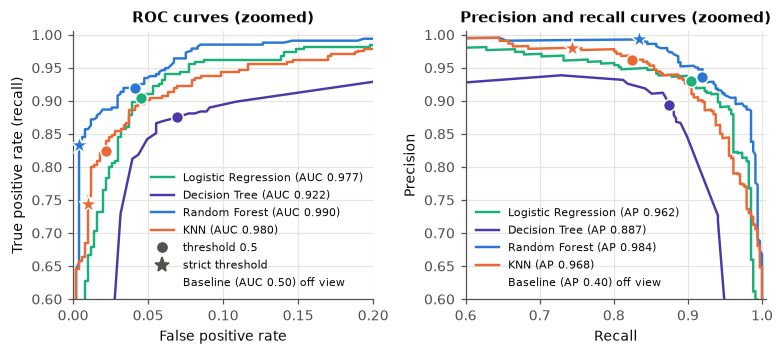

In [8]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.3))
for name in REAL:
    p = probabilities[name]
    fpr, tpr, _ = roc_curve(y, p)
    precision, recall, _ = precision_recall_curve(y, p)
    axes[0].plot(fpr, tpr, color=COLORS[name], lw=1.6,
                 label=f"{name} (AUC {roc_auc_score(y, p):.3f})")
    axes[1].plot(recall, precision, color=COLORS[name], lw=1.6,
                 label=f"{name} (AP {average_precision_score(y, p):.3f})")
    points = [(0.5, "o", 60)] + ([(strict_thresholds[name], "*", 150)] if name in strict_thresholds else [])
    for threshold, marker, size in points:
        s = scores(y, p, threshold)
        axes[0].scatter(1 - s["specificity"], s["recall"], marker=marker, s=size, color=COLORS[name],
                        edgecolor="white", linewidth=1, zorder=3)
        axes[1].scatter(s["recall"], s["precision"], marker=marker, s=size, color=COLORS[name],
                        edgecolor="white", linewidth=1, zorder=3)
# Zoomed in, since every model hugs the top corner. The baseline sits off this view.
axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)",
            title="ROC curves (zoomed)", xlim=(0, 0.2), ylim=(0.6, 1.005))
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision and recall curves (zoomed)",
            xlim=(0.6, 1.005), ylim=(0.6, 1.005))
markers = [Line2D([], [], marker="o", ls="", color=INK2, label="threshold 0.5"),
           Line2D([], [], marker="*", ms=10, ls="", color=INK2, label="strict threshold"),
           Line2D([], [], ls="", label="Baseline (AUC 0.50) off view")]
axes[0].legend(handles=axes[0].get_legend_handles_labels()[0] + markers, loc="lower right", fontsize=7.5)
baseline_note = Line2D([], [], ls="", label=f"Baseline (AP {y.mean():.2f}) off view")
axes[1].legend(handles=axes[1].get_legend_handles_labels()[0] + [baseline_note], loc="lower left", fontsize=7.5)
fig.tight_layout()
save_plot(fig, "03_roc_pr_curves.png")

Random Forest's curves sit on or above everyone else's almost everywhere, so its lead doesn't depend on one lucky threshold. It ranks emails best, with AP 0.984 and ROC AUC 0.990. KNN (AP 0.968) and logistic regression (0.962) are close to each other. The tree is clearly behind at AP 0.887 and AUC 0.922, and its curves are made of long straight pieces because every email in a leaf gets the same score.

The precision and recall panel is the more useful one [2]. Good models all pile into the top left corner of a ROC plot, so differences there look tiny even when they aren't. The PR view stretches out the high recall end. That's where logistic regression and KNN start sliding before Random Forest does, and where the tree falls off fast.

## 7. Checking that the difference isn't luck

Two models scored on the same emails aren't independent, so eyeballing whether their intervals overlap is the wrong test. McNemar's test looks only at the emails where two models disagree [3]. If they were equally good, each would be wrong on about half of those. The paired bootstrap does the same job for AP and F1 using the shared resamples from section 3. With four models there are six pairs, so the p values get a Holm correction [4].

In [9]:
wrong = pd.DataFrame({name: (probabilities[name] >= 0.5).astype(int) != y for name in REAL},
                     index=X_test.index)
pair_rows = []
for a, b in combinations(REAL, 2):
    only_a = int((wrong[a] & ~wrong[b]).sum())
    only_b = int((~wrong[a] & wrong[b]).sum())
    ap_boot = boot[a].average_precision - boot[b].average_precision
    f1_boot = boot[a].f1 - boot[b].f1
    pair_rows.append({"model_a": a, "model_b": b, "errors_only_a": only_a, "errors_only_b": only_b,
                      "mcnemar_p": binomtest(only_a, only_a + only_b, 0.5).pvalue,
                      "ap_diff": scores(y, probabilities[a])["average_precision"] -
                                 scores(y, probabilities[b])["average_precision"],
                      "ap_diff_ci": f"[{np.percentile(ap_boot, 2.5):+.3f}, {np.percentile(ap_boot, 97.5):+.3f}]",
                      "f1_diff": scores(y, probabilities[a])["f1"] - scores(y, probabilities[b])["f1"],
                      "f1_diff_ci": f"[{np.percentile(f1_boot, 2.5):+.3f}, {np.percentile(f1_boot, 97.5):+.3f}]"})
pairs = pd.DataFrame(pair_rows)

# Holm correction, since every extra pair is another chance of a fluke.
order = np.argsort(pairs.mcnemar_p.to_numpy())
running, holm = 0.0, np.empty(len(pairs))
for rank, i in enumerate(order):
    running = max(running, min(1.0, (len(pairs) - rank) * pairs.mcnemar_p.iloc[i]))
    holm[i] = running
pairs["mcnemar_p_holm"] = holm
pairs.to_csv(OUT / "pairwise_tests.csv", index=False)
display(pairs.round(4))

,model_a,model_b,errors_only_a,errors_only_b,mcnemar_p,ap_diff,ap_diff_ci,f1_diff,f1_diff_ci,mcnemar_p_holm
0,Logistic Regression,Decision Tree,23,45,0.0103,0.0752,"[+0.044, +0.109]",0.0328,"[+0.010, +0.059]",0.0414
1,Logistic Regression,Random Forest,24,17,0.3489,-0.0222,"[-0.039, -0.009]",-0.0109,"[-0.031, +0.009]",0.6978
2,Logistic Regression,KNN,21,36,0.0627,-0.0064,"[-0.026, +0.011]",0.0292,"[+0.006, +0.053]",0.1882
3,Decision Tree,Random Forest,39,10,0.0000,-0.0973,"[-0.131, -0.067]",-0.0437,"[-0.065, -0.024]",0.0002
4,Decision Tree,KNN,44,37,0.5052,-0.0816,"[-0.116, -0.048]",-0.0036,"[-0.031, +0.024]",0.6978
5,Random Forest,KNN,20,42,0.0071,0.0157,"[+0.007, +0.027]",0.0401,"[+0.016, +0.065]",0.0357


Three of the six pairs are clearly different after the correction. Random Forest beats KNN (it's wrong on 20 emails KNN gets right, against 42 the other way, Holm p = 0.036) and beats the tree by a lot (10 against 39, Holm p = 0.0002). Logistic regression beats the tree too (23 against 45, Holm p = 0.041).

The interesting pair is Random Forest and logistic regression. At the 0.5 threshold they can't be told apart. Logistic regression is wrong on 24 emails Random Forest gets right, Random Forest is wrong on 17 the other way, and p = 0.35. Their F1 difference interval [-0.031, +0.009] straddles zero as well. But Random Forest ranks emails better, with an AP lead of 0.022 [0.009, 0.039] that doesn't include zero. That ranking edge is exactly what a strict threshold needs, and section 8 shows it paying off.

KNN and the tree make about the same number of mistakes (p = 0.51). They just make different ones.

## 8. False positives vs false negatives

The two mistakes don't cost the same. A missed spam is mostly an annoyance, since you just delete it and move on (unless it's phishing). A real email buried in the spam folder can mean a missed job offer or an unpaid bill, and nobody notices until it's too late. So most people would rather see a bit more spam than lose real mail.

Part 3 locked a strict threshold for Random Forest and KNN before touching the test set, picked on out of fold predictions as the highest recall that still keeps precision at 98% or more. Section 2 showed the same rule finds nothing for Part 2's models. Fig. 4 puts the strict thresholds next to the default 0.5, with false alarms as bars going left and missed spam as bars going right. Faded bars are the strict thresholds.

,model,policy,threshold,fp,fn,precision,recall,specificity
0,Logistic Regression,default,0.500,23,32,0.930,0.905,0.955
1,Decision Tree,default,0.500,35,42,0.894,0.875,0.931
2,Random Forest,default,0.500,21,27,0.936,0.920,0.958
3,Random Forest,strict,0.735,2,56,0.993,0.833,0.996
4,KNN,default,0.500,11,59,0.962,0.824,0.978
5,KNN,strict,0.633,5,86,0.980,0.744,0.990


Random Forest: strict threshold wins once a false alarm costs more than 1.5 missed spams
KNN: strict threshold wins once a false alarm costs more than 4.5 missed spams


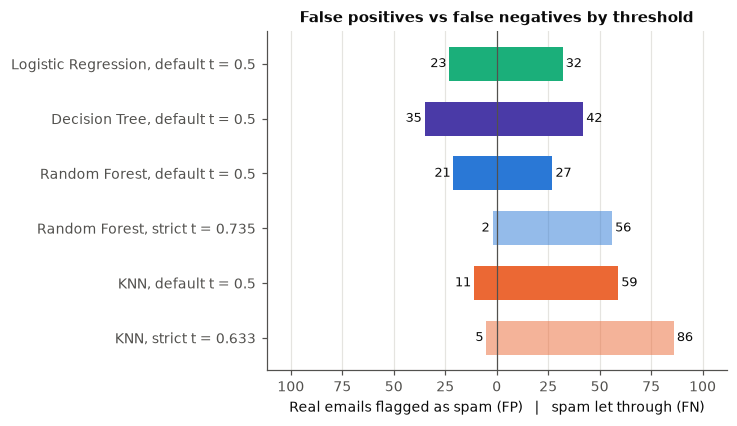

In [10]:
policy_rows = []
for name in REAL:
    strict = [("strict", strict_thresholds[name])] if name in strict_thresholds else []
    for policy, threshold in [("default", 0.5)] + strict:
        s = scores(y, probabilities[name], threshold)
        policy_rows.append({"model": name, "policy": policy, "threshold": threshold,
                            "fp": s["fp"], "fn": s["fn"], "precision": s["precision"],
                            "recall": s["recall"], "specificity": s["specificity"]})
policies = pd.DataFrame(policy_rows)
policies.to_csv(OUT / "fp_fn_by_threshold.csv", index=False)
display(policies.round(3))

# How many missed spams one false alarm has to be worth before the strict threshold pays off.
for name, group in policies.groupby("model", sort=False):
    if len(group) == 2:
        default, strict = group.iloc[0], group.iloc[1]
        ratio = (strict.fn - default.fn) / (default.fp - strict.fp)
        print(f"{name}: strict threshold wins once a false alarm costs more than {ratio:.1f} missed spams")

fig, ax = plt.subplots(figsize=(5.4, 0.5 * len(policies) + 1.0))
for row_number, row in enumerate(policies.itertuples()):
    alpha = 1.0 if row.policy == "default" else 0.5
    ax.barh(row_number, -row.fp, height=0.62, color=COLORS[row.model], alpha=alpha)
    ax.barh(row_number, row.fn, height=0.62, color=COLORS[row.model], alpha=alpha)
    ax.text(-row.fp - 1.5, row_number, row.fp, ha="right", va="center", fontsize=8.5)
    ax.text(row.fn + 1.5, row_number, row.fn, ha="left", va="center", fontsize=8.5)
limit = max(policies.fp.max(), policies.fn.max()) * 1.3
ax.set_xlim(-limit, limit)
ticks = [t for t in ax.get_xticks() if abs(t) <= limit]
ax.set_xticks(ticks, [str(int(abs(t))) for t in ticks])
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(range(len(policies)),
              [f"{r.model}, {r.policy} t = {r.threshold:.3g}" for r in policies.itertuples()])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Real emails flagged as spam (FP)   |   spam let through (FN)")
ax.set_title("False positives vs false negatives by threshold")
save_plot(fig, "04_fp_fn_tradeoff.png")

At 0.5, KNN makes the fewest false alarms (11) and Random Forest the fewest misses (27). The tree is worst on both.

The strict threshold does what it's supposed to. Random Forest drops from 21 false alarms to 2 and its precision climbs to 0.993, but it misses 29 more spams (56 instead of 27). KNN goes from 11 false alarms to 5 and misses 27 more.

Whether that trade pays off depends on how many missed spams one lost real email is worth. For Random Forest the strict threshold wins once a false alarm costs more than about 1.5 missed spams. That's a really low bar, and almost anyone would clear it. KNN needs a false alarm to be worth more than 4.5 missed spams first. Now compare two rows. Random Forest at its strict threshold beats KNN at 0.5 on both errors at once (2 vs 11 false alarms, 56 vs 59 misses). If we had to ship one of these, it'd be Random Forest with the strict threshold.

One caveat. The 98% precision target held on the test set (0.993 and 0.980), but the threshold came from out of fold models trained on less data, so treat it as a target and not a promise for new mail.

## 9. Where the models go wrong

The first two tables count how many models got each test email wrong, and which ones. Then the heatmap shows what Random Forest's mistakes actually look like, using the token columns from Part 1's EDA, where each cell is the share of emails in that row's group containing that token.

In [11]:
n_wrong = wrong.sum(axis=1)
true_class = np.where(y == 1, "spam missed (FN)", "real email flagged (FP)")
display(pd.crosstab(n_wrong.rename("models that got it wrong"), true_class))
pattern = wrong.rename(columns=SHORT).apply(lambda row: " + ".join(row.index[row]) or "nobody", axis=1)
overlap = pd.crosstab(pattern.rename("wrong for"), true_class)
overlap = overlap.loc[overlap.sum(axis=1).sort_values(ascending=False).index]
overlap.to_csv(OUT / "error_overlap.csv")
display(overlap)

col_0,real email flagged (FP),spam missed (FN)
models that got it wrong,,
0,457,255
1,26,40
2,11,17
3,6,10
4,6,14


col_0,real email flagged (FP),spam missed (FN)
wrong for,,
nobody,457,255
DT,17,10
KNN,1,24
LR + DT + RF + KNN,6,14
LR,5,4
LR + KNN,2,7
DT + RF,5,2
DT + KNN,0,6
LR + DT + RF,4,2


,emails,median tracked words present,median longest capital run
"Real email, kept (TN)",485,6.0,11.0
"Real email, flagged (FP)",21,7.0,25.0
"Spam, missed (FN)",27,4.0,12.0
"Spam, caught (TP)",309,10.0,47.0


,Logistic Regression,Decision Tree,Random Forest,KNN
recall on spam with 4 or fewer tracked words,0.732,0.714,0.750,0.589
recall on spam with more than 4,0.939,0.907,0.954,0.871
median tracked words in missed spam,6.500,7.000,4.000,5.000
median tracked words in real email,6.000,6.000,6.000,6.000


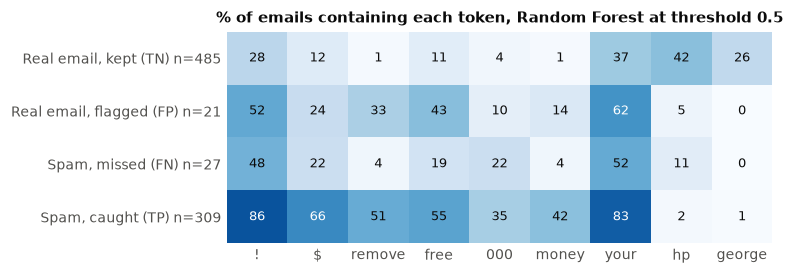

In [12]:
TOKENS = {"char_freq_!": "!", "char_freq_$": "$", "word_freq_remove": "remove", "word_freq_free": "free",
          "word_freq_000": "000", "word_freq_money": "money", "word_freq_your": "your",
          "word_freq_hp": "hp", "word_freq_george": "george"}
predicted = (probabilities[best] >= 0.5).astype(int)
outcome = pd.Series(np.select([(y == 0) & (predicted == 0), (y == 0) & (predicted == 1),
                               (y == 1) & (predicted == 0), (y == 1) & (predicted == 1)],
                              ["Real email, kept (TN)", "Real email, flagged (FP)",
                               "Spam, missed (FN)", "Spam, caught (TP)"], default=""),
                    index=X_test.index)
groups = ["Real email, kept (TN)", "Real email, flagged (FP)", "Spam, missed (FN)", "Spam, caught (TP)"]
presence = (X_test[list(TOKENS)] > 0).groupby(outcome).mean().loc[groups].rename(columns=TOKENS) * 100

word_columns = [c for c in X_test.columns if c.startswith("word_freq_")]
tracked = (X_test[word_columns] > 0).sum(axis=1)
extra = pd.DataFrame({"emails": outcome.value_counts().loc[groups],
                      "median tracked words present": tracked.groupby(outcome).median().loc[groups],
                      "median longest capital run": X_test["capital_run_length_longest"].groupby(outcome).median().loc[groups]})
presence.join(extra).to_csv(OUT / "error_profile.csv")
display(extra)

# Short spam with few tracked words is the hard case, and KNN struggles with it most.
tracked = tracked.to_numpy()
by_length = pd.DataFrame({name: {
    "recall on spam with 4 or fewer tracked words": (probabilities[name][(y == 1) & (tracked <= 4)] >= 0.5).mean(),
    "recall on spam with more than 4": (probabilities[name][(y == 1) & (tracked > 4)] >= 0.5).mean(),
    "median tracked words in missed spam": np.median(tracked[(y == 1) & (probabilities[name] < 0.5)]),
    "median tracked words in real email": np.median(tracked[y == 0])} for name in REAL})
by_length.to_csv(OUT / "recall_by_email_length.csv")
display(by_length.round(3))

fig, ax = plt.subplots(figsize=(6.4, 2.5))
ax.imshow(presence.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
for i in range(presence.shape[0]):
    for j in range(presence.shape[1]):
        value = presence.iat[i, j]
        ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8.5,
                color="white" if value > 55 else INK)
ax.set_xticks(range(presence.shape[1]), presence.columns)
ax.set_yticks(range(len(groups)), [f"{g} n={extra.emails[g]}" for g in groups])
ax.tick_params(length=0)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title(f"% of emails containing each token, {best} at threshold 0.5")
save_plot(fig, "05_error_profile.png")

Most test emails are easy. 712 of the 842 fool nobody. At the other end, 20 fool all four models, 6 real emails and 14 spams, so they're probably past what these 57 features can tell apart. Random Forest has by far the fewest solo mistakes, just 5 emails that only it gets wrong. The tree has the most at 27, mostly false alarms (17), and KNN's 25 solo mistakes are almost all missed spam (24).

Fig. 5 explains a lot. The real emails that Random Forest flags read like ads. 43% of them contain "free", compared with 11% of the real mail it keeps, and 33% contain "remove", compared with 1%. They also almost never contain "hp" (5% vs 42%) or "george" (0% vs 26%). That second part matters more than it looks. "hp" is the strongest real mail signal in the whole dataset (r = -0.27 with the spam label in Part 1), and the false alarms just don't have it.

Missed spam is the opposite. It's quiet spam. Only 4% of missed spams contain "remove" and 4% contain "money", next to 51% and 42% of caught spam. They're short too, with a median of 4 tracked words and a longest capital run of 12, against 10 words and 47 for the spam that gets caught. There's just not much for any model to grab onto.

In [13]:
mean_probability = pd.DataFrame(probabilities, index=X_test.index)[REAL].mean(axis=1)
always_wrong = wrong.all(axis=1)
examples = pd.concat([
    mean_probability[(y == 1) & ~wrong.any(axis=1)].nlargest(1),
    mean_probability[(y == 0) & ~wrong.any(axis=1)].nsmallest(1),
    mean_probability[always_wrong & (y == 0)].nlargest(2),
    mean_probability[always_wrong & (y == 1)].nsmallest(2),
]).index
example_table = pd.DataFrame({"true label": np.where(y_test.loc[examples] == 1, "spam", "non-spam")},
                             index=examples)
for name in REAL:
    example_table[f"{name} p(spam)"] = pd.Series(probabilities[name], index=X_test.index).loc[examples]
example_table = example_table.join(X_test.loc[examples, list(TOKENS) + ["capital_run_length_longest"]]
                                   .rename(columns=TOKENS))
example_table["tracked words present"] = (X_test.loc[examples, word_columns] > 0).sum(axis=1)
example_table.index.name = "cleaned_row_id"
example_table.to_csv(OUT / "example_predictions.csv")
display(example_table.round(2))

,true label,Logistic Regression p(spam),Decision Tree p(spam),Random Forest p(spam),KNN p(spam),!,$,remove,free,000,money,your,hp,george,capital_run_length_longest,tracked words present
cleaned_row_id,,,,,,,,,,,,,,,,
1000,spam,1.00,1.00,1.00,1.00,0.50,0.00,2.20,0.00,0.0,0.00,1.10,0.00,0.00,148,11
2659,non-spam,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,8.69,4.34,11,12
2312,non-spam,0.98,0.98,0.98,1.00,0.87,0.10,0.41,0.41,0.2,1.04,2.29,0.00,0.00,214,15
3027,non-spam,1.00,0.98,0.90,0.72,0.00,0.66,2.22,0.00,0.0,0.00,0.00,0.00,0.00,25,2
1550,spam,0.03,0.13,0.26,0.19,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,38,1
582,spam,0.37,0.03,0.10,0.16,0.00,0.00,0.00,0.00,0.0,0.00,1.63,0.00,0.00,1,2


The table has two easy calls and four emails that fooled all four models (row IDs are `cleaned_row_id` values). Row 1000 is obvious spam with "remove" and a 148 character run of capitals, and every model gives it 1.00. Row 2659 is the opposite, full of "hp" and "george", and every model gives it 0.00.

The errors make sense once you see them. Row 2312 is a real email with nearly every spam token plus a 214 character run of capitals, and all four models are at least 0.98 sure it's spam. Honestly, we'd have flagged it too. Row 3027 is real mail with only two tracked words, but "remove" makes up 2.2% of its words, and logistic regression gives it 1.00. Rows 1550 and 582 are spam with one or two tracked words and basically nothing else, so the models have nothing to work with. Without the original text we can't tell whether any of these labels are wrong. All we can say is that the features point the other way.

## 10. Subgroup check on the donor's own words

All of the real email in Spambase comes from one person's work and personal inbox at HP Labs. The UCI notes say so directly and warn that "george" and the area code "650" are real mail signals that only make sense for a personal filter [5]. So the real test emails get split by whether they contain any of the four donor words Part 1 named in its summary, george, hp, hpl and 650. A donor word shows up in about 55% of real emails and about 5% of spam, in both train and test.

If the models lean on those words, real emails without them should get flagged a lot more often. Those emails are also the closest thing this dataset has to someone else's inbox, where george and hp would never come up. The error bars are Wilson 95% intervals [6]. The small weights table comes from logistic regression, whose features are standardized, so the sizes of its weights can be compared directly.

train: donor word in 54.8% of real emails and 5.0% of spam
test: donor word in 54.9% of real emails and 4.5% of spam


,!,$,remove,free,000,money,your,business
% of real emails WITH a donor word,24.0,15.0,1.5,8.5,3.5,2.0,39.6,15.8
% of real emails WITHOUT one,35.7,6.2,1.2,9.9,2.0,2.6,32.8,3.6


,weight
word_freq_george,-4.02
word_freq_hp,-2.48
word_freq_edu,-1.34
word_freq_meeting,-1.22
word_freq_cs,-1.19
char_freq_#,0.87
word_freq_3d,0.98
capital_run_length_longest,1.05
word_freq_remove,1.05
char_freq_$,1.23


,model,subgroup,rate,errors,emails,value,ci_low,ci_high
0,Logistic Regression,has a donor word,false alarm rate on real email,2,278,0.007,0.002,0.026
1,Logistic Regression,has a donor word,miss rate on spam,5,15,0.333,0.152,0.583
2,Logistic Regression,no donor word,false alarm rate on real email,21,228,0.092,0.061,0.137
3,Logistic Regression,no donor word,miss rate on spam,27,321,0.084,0.058,0.120
4,Decision Tree,has a donor word,false alarm rate on real email,9,278,0.032,0.017,0.060
5,Decision Tree,has a donor word,miss rate on spam,6,15,0.400,0.198,0.643
6,Decision Tree,no donor word,false alarm rate on real email,26,228,0.114,0.079,0.162
7,Decision Tree,no donor word,miss rate on spam,36,321,0.112,0.082,0.151
8,Random Forest,has a donor word,false alarm rate on real email,2,278,0.007,0.002,0.026
9,Random Forest,has a donor word,miss rate on spam,4,15,0.267,0.109,0.520


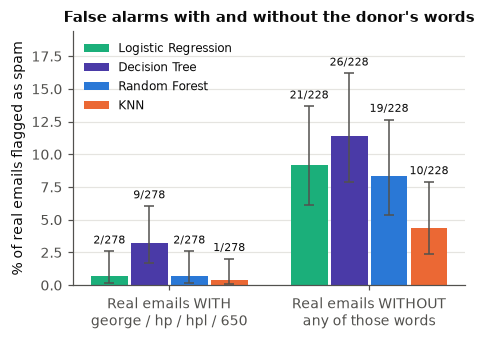

In [14]:
DONOR = ["word_freq_george", "word_freq_hp", "word_freq_hpl", "word_freq_650"]
for split_name, X_part, y_part in [("train", X_train, y_train), ("test", X_test, y_test)]:
    has = (X_part[DONOR] > 0).any(axis=1)
    print(f"{split_name}: donor word in {has[y_part == 0].mean():.1%} of real emails "
          f"and {has[y_part == 1].mean():.1%} of spam")

# Are real emails without donor words just spammier? Checked on training data only.
spam_tokens = {"char_freq_!": "!", "char_freq_$": "$", "word_freq_remove": "remove", "word_freq_free": "free",
               "word_freq_000": "000", "word_freq_money": "money", "word_freq_your": "your",
               "word_freq_business": "business"}
real_train = (y_train == 0).to_numpy()
donor_train = (X_train[DONOR] > 0).any(axis=1).to_numpy()
token_rates = pd.DataFrame({
    "% of real emails WITH a donor word": (X_train.loc[real_train & donor_train, list(spam_tokens)] > 0).mean() * 100,
    "% of real emails WITHOUT one": (X_train.loc[real_train & ~donor_train, list(spam_tokens)] > 0).mean() * 100,
}).rename(index=spam_tokens)
token_rates.to_csv(OUT / "spam_tokens_in_real_email_by_donor_word.csv")
display(token_rates.T.round(1))

# Logistic regression works on standardized features, so the sizes of its weights can be compared.
weights = pd.Series(fitted_part2["Logistic Regression"][-1].coef_[0], index=X_train.columns).sort_values()
weights.rename("weight").to_csv(OUT / "logistic_regression_weights.csv")
display(pd.concat([weights.head(5), weights.tail(5)]).rename("weight").round(2).to_frame())

def wilson(k, n, z=1.96):
    centre = (k / n + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(k / n * (1 - k / n) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

has_donor = (X_test[DONOR] > 0).any(axis=1).to_numpy()
subgroup_rows = []
for name in REAL:
    predicted = probabilities[name] >= 0.5
    for label, mask in [("has a donor word", has_donor), ("no donor word", ~has_donor)]:
        for kind, cls in [("false alarm rate on real email", 0), ("miss rate on spam", 1)]:
            rows = mask & (y == cls)
            k = int((predicted[rows] != cls).sum())
            low, high = wilson(k, rows.sum())
            subgroup_rows.append({"model": name, "subgroup": label, "rate": kind, "errors": k,
                                  "emails": int(rows.sum()), "value": k / rows.sum(),
                                  "ci_low": low, "ci_high": high})
subgroups = pd.DataFrame(subgroup_rows)
subgroups.to_csv(OUT / "donor_word_subgroups.csv", index=False)
display(subgroups.round(3))

alarms = subgroups[subgroups.rate == "false alarm rate on real email"]
labels = ["has a donor word", "no donor word"]
width = 0.8 / len(REAL)
fig, ax = plt.subplots(figsize=(4.6, 3.0))
for k, name in enumerate(REAL):
    part = alarms[alarms.model == name].set_index("subgroup").loc[labels]
    x = np.arange(2) - 0.4 + width * (k + 0.5)
    ax.bar(x, part.value * 100, width=width * 0.92, color=COLORS[name], label=name,
           yerr=[(part.value - part.ci_low) * 100, (part.ci_high - part.value) * 100],
           capsize=3, error_kw={"lw": 1, "ecolor": INK2})
    for xi, row in zip(x, part.itertuples()):
        ax.text(xi, row.ci_high * 100 + 0.6, f"{row.errors}/{row.emails}", ha="center", fontsize=7.5)
ax.set_ylim(0, alarms.ci_high.max() * 100 * 1.2)
ax.set_xticks([0, 1], ["Real emails WITH\ngeorge / hp / hpl / 650", "Real emails WITHOUT\nany of those words"])
ax.set_ylabel("% of real emails flagged as spam")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", fontsize=8)
ax.set_title("False alarms with and without the donor's words")
save_plot(fig, "06_donor_word_false_alarms.png")

This is the biggest finding in Part 4, and all four models show it. Random Forest flags 0.7% of the real emails that contain a donor word (2 of 278) and 8.3% of the ones that don't (19 of 228). Logistic regression goes from 0.7% to 9.2%, the tree from 3.2% to 11.4%, and KNN from 0.4% to 4.4%. None of the intervals overlap.

So each headline false alarm rate is really an average of two very different groups. On mail that looks like the donor's the filters are close to perfect, but on everything else three of the four models run at about double their headline rate. A new user's real mail would land almost entirely in that second group, since it won't mention George or HP.

And it's not because those emails are spammier. In the training data, real emails without a donor word contain "$" and "business" less often than the donor's own mail (6% vs 15% and 4% vs 16%). Only "!" is more common in them (36% vs 24%), and the other spam tokens show up at about the same rates. What's going on is that the donor words work like a pass. When they're there, the models forgive a "$" or a "free". When they're missing, nothing offsets those tokens.

Logistic regression spells it out in its weights. The two biggest weights in the whole model are george (-4.0) and hp (-2.5), bigger than its strongest spam signal, "$" (+1.2).

Spam that happens to contain a donor word gets missed more often too (3 to 6 of 15, depending on the model), but 15 emails is too few to conclude anything.

## 11. Changing one modeling choice by dropping the donor words

The subgroup check shows where the errors are, but it doesn't show whether the models need those four words. So all four models get refit with their final settings, once with all 57 features and once without george, hp, hpl and 650. CV uses Part 3's five outer folds, and the test set is the same 842 emails. The full refits reproduce the test predictions used above exactly, and the code checks that.

These CV numbers keep each model's settings fixed on every fold, so they're slightly higher than the nested results in section 4. That's fine because both versions get the same treatment. The settings aren't retuned for the smaller feature set, which gives the full models a small edge.

In [15]:
rebuilt = {
    **PART2_MODELS,
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1, **locked["best_params"]["RF"]),
    "KNN": Pipeline([("scale", StandardScaler()),
                     ("knn", KNeighborsClassifier(algorithm="brute", n_jobs=1))]).set_params(**locked["best_params"]["KNN"]),
}

ablation_rows = []
for name, model in rebuilt.items():
    for features, dropped in [("all 57 features", []), ("without george/hp/hpl/650", DONOR)]:
        fold_ap = []
        for fold in range(1, 6):
            fitted = clone(model).fit(X_train[folds != fold].drop(columns=dropped), y_train[folds != fold])
            fold_ap.append(average_precision_score(
                y_train[folds == fold], fitted.predict_proba(X_train[folds == fold].drop(columns=dropped))[:, 1]))
        fitted = clone(model).fit(X_train.drop(columns=dropped), y_train)
        p = fitted.predict_proba(X_test.drop(columns=dropped))[:, 1]
        if not dropped:
            assert np.allclose(p, probabilities[name]), f"Refit {name} doesn't match its saved predictions"
        s = scores(y, p)
        ablation_rows.append({"model": name, "features": features,
                              "cv_ap_mean": np.mean(fold_ap), "cv_ap_sd": np.std(fold_ap, ddof=1),
                              "test_ap": s["average_precision"], "test_f1": s["f1"],
                              "fp": s["fp"], "fn": s["fn"],
                              "false_alarms_real_with_donor_word": (p[has_donor & (y == 0)] >= 0.5).mean(),
                              "false_alarms_real_without_donor_word": (p[~has_donor & (y == 0)] >= 0.5).mean()})
ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(OUT / "donor_word_ablation.csv", index=False)
display(ablation.round(4))

,model,features,cv_ap_mean,cv_ap_sd,test_ap,test_f1,fp,fn,false_alarms_real_with_donor_word,false_alarms_real_without_donor_word
0,Logistic Regression,all 57 features,0.9448,0.0174,0.9619,0.9170,23,32,0.0072,0.0921
1,Logistic Regression,without george/hp/hpl/650,0.9304,0.0156,0.9454,0.8937,23,46,0.0324,0.0614
2,Decision Tree,all 57 features,0.8763,0.0170,0.8868,0.8842,35,42,0.0324,0.1140
3,Decision Tree,without george/hp/hpl/650,0.8432,0.0193,0.8621,0.8778,36,45,0.0540,0.0921
4,Random Forest,all 57 features,0.9767,0.0114,0.9841,0.9279,21,27,0.0072,0.0833
5,Random Forest,without george/hp/hpl/650,0.9712,0.0107,0.9791,0.9198,21,32,0.0216,0.0658
6,KNN,all 57 features,0.9629,0.0090,0.9684,0.8878,11,59,0.0036,0.0439
7,KNN,without george/hp/hpl/650,0.9581,0.0092,0.9661,0.8680,7,73,0.0000,0.0307


The simpler models lean on the donor words hardest. Dropping them costs logistic regression 0.014 in mean CV AP (0.945 to 0.930) and the tree 0.033 (0.876 to 0.843), while Random Forest and KNN only lose about 0.005. That fits the weights in section 10. Logistic regression's test F1 falls from 0.917 to 0.894, and it misses 14 more spams.

The pass effect shows up directly too. Without the four words, Random Forest's false alarm rate on the donor's own real mail goes from 0.7% to 2.2% and logistic regression's from 0.7% to 3.2%, while their rates on the other real mail go down. The tree shifts the same way. The two groups move closer but stay far apart, so four words explain part of the difference and not all of it. KNN reacts differently. It flags fewer real emails in both groups and misses 14 more spams, so it mostly just got more cautious.

Still, no model falls apart without them. Most of what they learned is genuine spam vocabulary.

## 12. Limitations and responsible use

**One person's inbox from 1999.** Every real email in Spambase comes from a single HP Labs employee. Section 10 shows what that does to the results, close to perfect on mail like the donor's and roughly twice as error prone on everything else. So every number in this notebook really answers "how well can we filter this one inbox". Not "how well can we filter email".

**Old spam.** The UCI notes describe the spam as ads, money making schemes, chain letters and porn. Today it's phishing, link tricks, image spam and text written to sound normal. None of that shows up in 57 word and character counts, so these scores would almost certainly drop on current mail.

**Easy to dodge.** The features count 48 fixed words and 6 characters. Writing "fr ee" or putting the ad inside an image gets past them, and word order and context are gone completely.

**Labels and text.** The labels reflect one person's idea of spam. Three pairs of emails even have identical features but opposite labels. And with no raw text, we can describe what the errors look like but can't check whether some of them are labeling mistakes.

**One test split.** 842 emails is enough for the main conclusions, but the intervals are still a few points wide (Random Forest's F1 sits somewhere around 0.91 to 0.95). The bootstrap only resamples this same dataset. It says nothing about a different inbox.

**Responsible use.** A false alarm hides a real email, so a filter like this should only move mail to a spam folder people can check, never delete it. The strict threshold is the safer default, and only Random Forest and KNN rank emails well enough to use one. The subgroup result is also a fairness problem in miniature. Anyone whose mail doesn't look like the training inbox gets no pass at all, and if their normal email also mentions prices or deals, like a small seller's would, it gets flagged far more often. A real filter also reads private email, so it needs consent and careful data handling, even though Spambase itself only stores word counts.

**What we'd do next.**
1. Train and test on a newer corpus with many users, like Enron Spam or the SpamAssassin public corpus, and hold whole users out of training so the test really is a new inbox.
2. Use the raw text, for example TF-IDF with a linear model, plus header and link features. That would also let us read the errors.
3. Drop or blind the donor words like the UCI notes suggest, and always report the subgroup false alarm rate next to the overall one.
4. Set thresholds from real error costs, and check calibration so a predicted 0.9 means roughly a 90% chance of spam.

## 13. Final checks

Section 2 already checked the rebuilt Part 2 models against Part 2's own table. This cell does the same for Part 3's models, and it also confirms that each point estimate sits inside its interval and that train and test share no rows.

In [16]:
part3_metrics = pd.read_csv(part3 / "test_metrics.csv")
for name, old in PART3_NAMES.items():
    reported_part3 = part3_metrics[(part3_metrics.model == old) & (part3_metrics.threshold == 0.5)].iloc[0]
    mine = scores(y, probabilities[name])
    for metric in ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision", "fp", "fn"]:
        assert np.isclose(reported_part3[metric], mine[metric]), (name, metric)
assert ((test_table.ci_low <= test_table.value + 1e-12) & (test_table.value <= test_table.ci_high + 1e-12)).all()
assert set(X_train.index).isdisjoint(X_test.index)
assert len(y) == 842 and len(report_table) == len(MODELS)
print("All checks passed.")
print("Results saved in:", OUT.relative_to(RESULTS_DIR.parent).as_posix())
print("Figures saved in:", FIG.relative_to(FIGURES_DIR.parent).as_posix())

All checks passed.
Results saved in: results/part4
Figures saved in: figures/part4


## References

[1] B. Efron and R. J. Tibshirani, *An Introduction to the Bootstrap*. New York, NY, USA: Chapman & Hall, 1993.

[2] T. Saito and M. Rehmsmeier, "The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets," *PLoS ONE*, vol. 10, no. 3, Art. no. e0118432, 2015.

[3] T. G. Dietterich, "Approximate statistical tests for comparing supervised classification learning algorithms," *Neural Comput.*, vol. 10, no. 7, pp. 1895-1923, 1998.

[4] S. Holm, "A simple sequentially rejective multiple test procedure," *Scand. J. Statist.*, vol. 6, no. 2, pp. 65-70, 1979.

[5] M. Hopkins, E. Reeber, G. Forman, and J. Suermondt, "Spambase," UCI Machine Learning Repository, 1999. doi: 10.24432/C53G6X.

[6] E. B. Wilson, "Probable inference, the law of succession, and statistical inference," *J. Amer. Statist. Assoc.*, vol. 22, no. 158, pp. 209-212, 1927.